# 3 · Segmentación, políticas de retención validadas con el holdout y servicio

En este notebook:
1. Cruzamos $P(\text{vivo})$, frecuencia y CLV neto para construir **5 segmentos accionables** y vemos dónde se equivoca el modelo.
2. Comparamos **4 políticas de campaña de reactivación** con lo que **realmente gastaron** esos clientes en los 6 meses de prueba (no hubo campaña en los datos, así que medimos cuánto tendría que funcionar cada política para pagarse).
3. Separamos esa validación del **escenario económico con supuestos** y mostramos cuánto depende de ellos.
4. Probamos la API FastAPI y la app Streamlit.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))

from clv import config, datos, evaluacion, predecir, segmentacion
from clv.graficos import estilo, num, AZUL, NARANJA, VERDE, AMARILLO, GRIS
estilo()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
from fastapi.testclient import TestClient
from api.main import app

## 3.1 · Los 5 segmentos estratégicos de la cartera

In [2]:
segmentos = pd.read_csv(config.REPORTES / "resumen_segmentos.csv")
segmentos[["segmento", "n_clientes", "pct_clientes", "frecuencia_media", "inactividad_media_dias", "prob_vivo_media",
           "prob_recompra_media", "tasa_recompra_real", "clv_neto_medio_gbp", "ingreso_esperado_total_gbp",
           "ingreso_real_holdout_gbp", "ratio_ingreso_real_vs_esperado", "pct_ingreso_real"]]

,segmento,n_clientes,pct_clientes,frecuencia_media,inactividad_media_dias,prob_vivo_media,prob_recompra_media,tasa_recompra_real,clv_neto_medio_gbp,ingreso_esperado_total_gbp,ingreso_real_holdout_gbp,ratio_ingreso_real_vs_esperado,pct_ingreso_real
0,Campeones activos,1598,32.322,9.118,52.511,0.950,0.824,0.849,454.388,"2,505,257.143","2,955,954.560",1.180,80.406
1,En riesgo de alto valor,197,3.985,4.695,270.036,0.518,0.382,0.406,113.632,"77,236.329","92,640.730",1.199,2.520
2,Nuevos / prometedores,2299,46.501,0.314,240.788,0.958,0.329,0.305,58.385,"463,101.613","397,154.550",0.858,10.803
3,Regulares / ocasionales,811,16.404,2.212,168.768,0.854,0.525,0.527,92.172,"257,917.820","216,035.240",0.838,5.876
4,Inactivos / perdidos,39,0.789,9.641,327.051,0.075,0.062,0.205,26.774,"3,602.796","14,498.110",4.024,0.394


In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 3.8))
y = np.arange(len(segmentos))
a1.barh(y - 0.2, segmentos["prob_recompra_media"] * 100, height=0.4, color=AZUL, label="P(recompra) predicha")
a1.barh(y + 0.2, segmentos["tasa_recompra_real"] * 100, height=0.4, color=NARANJA, label="Recompra real")
a1.set_yticks(y, segmentos["segmento"]); a1.invert_yaxis(); a1.set_xlabel("%"); a1.legend(fontsize=8); a1.set_title("Recompra predicha vs. real por segmento")
a2.barh(y, segmentos["ratio_ingreso_real_vs_esperado"], color=[AZUL, NARANJA, VERDE, AMARILLO, GRIS])
a2.axvline(1, color=GRIS, linestyle=":"); a2.set_yticks(y, segmentos["segmento"]); a2.invert_yaxis()
a2.set_xlabel("Ingreso real / ingreso esperado"); a2.set_title("¿Dónde se equivoca el modelo en dinero?")
plt.tight_layout(); plt.show()

**Limitación — «Inactivos / perdidos»:** el modelo les da $P(\text{vivo})$ medio de 7,5 % (recompra predicha 6,2 %), pero el **20,5 %** volvió a comprar y gastaron unas **4 veces** lo esperado (14.498 frente a 3.603 GBP). Son solo 39 clientes (0,4 % del ingreso) muy frecuentes con un silencio largo; BG/NBD los da por perdidos demasiado pronto, probablemente porque compran por temporadas (la tasa de compra constante no captura ese patrón). En dinero el error es pequeño, pero conviene no excluirlos del todo: el *retargeting* pasivo de bajo costo es la acción razonable.

In [4]:
cartera = pd.read_csv(config.REPORTES / "cartera_clientes.csv", dtype={"customer_id": str})
inact = cartera[cartera["segmento"] == "Inactivos / perdidos"]
inact[["customer_id", "frecuencia", "inactividad_dias", "prob_vivo", "prob_recompra", "ingreso_esperado", "compras_holdout", "gasto_holdout_acotado"]].sort_values("gasto_holdout_acotado", ascending=False).head(10)

,customer_id,frecuencia,inactividad_dias,prob_vivo,prob_recompra,ingreso_esperado,compras_holdout,gasto_holdout_acotado
4203,17396,6,188.000,0.143,0.136,122.948,3,"5,529.000"
4409,17651,4,315.000,0.041,0.034,31.139,9,"3,945.000"
3476,16549,23,151.000,0.035,0.035,111.936,7,"3,915.410"
2215,15043,4,280.000,0.182,0.149,168.475,1,537.000
3991,17157,15,297.000,0.004,0.004,5.536,2,319.000
3494,16569,3,448.000,0.199,0.124,71.798,1,124.200
4677,17969,18,178.000,0.187,0.185,139.292,1,103.000
4926,18268,4,408.000,0.193,0.137,80.260,1,25.500
965,13564,24,171.000,0.057,0.057,262.481,0,0.000
868,13446,10,247.000,0.116,0.111,138.408,0,0.000


## 3.2 · Políticas de rescate validadas con el gasto real del periodo de prueba

Las cuatro políticas solo usan información hasta el corte. Para cada una medimos con el holdout:
- **Recompra real sin campaña:** si es alta, el incentivo se lo lleva gente que iba a volver igual.
- **Margen real por contacto** y **uplift de equilibrio** (cuánto tendría que subir ese margen para pagar 6 GBP por contacto).
- **Tasa de rescate de equilibrio:** de los contactados que **no** volvieron, qué % habría que recuperar (a su ritmo de gasto histórico) para pagar la campaña, con IC 95 % bootstrap.

Sin un experimento A/B no se puede medir el efecto causal: estas cifras dicen cuánto tendría que funcionar cada política, no cuánto funciona.

,politica,clientes_contactados,costo_campana_gbp,tasa_recompra_real_pct,margen_real_holdout_gbp,margen_real_por_contacto_gbp,uplift_equilibrio_pct,clientes_sin_recompra,margen_historico_perdido_gbp,tasa_rescate_equilibrio_pct,tasa_rescate_equilibrio_ic95_inf,tasa_rescate_equilibrio_ic95_sup
0,1. Contactar a todos con > 60 días sin comprar,3362,"20,172.000",39.054,"293,088.537",87.177,6.883,2049,"234,080.030",8.618,7.878,9.375
1,2. Regla RFM (frecuencia >= 2 e inactividad 60...,1016,"6,096.000",64.665,"186,264.057",183.331,3.273,359,"90,061.109",6.769,5.481,8.336
2,3. Top 20 % gasto histórico con > 60 d inactiv...,334,"2,004.000",69.760,"117,496.434",351.786,1.706,101,"67,585.299",2.965,2.332,3.945
3,4. BG/NBD + Gamma-Gamma (zona de riesgo y bene...,190,"1,140.000",40.000,"27,485.502",144.661,4.148,114,"31,820.284",3.583,2.521,5.029


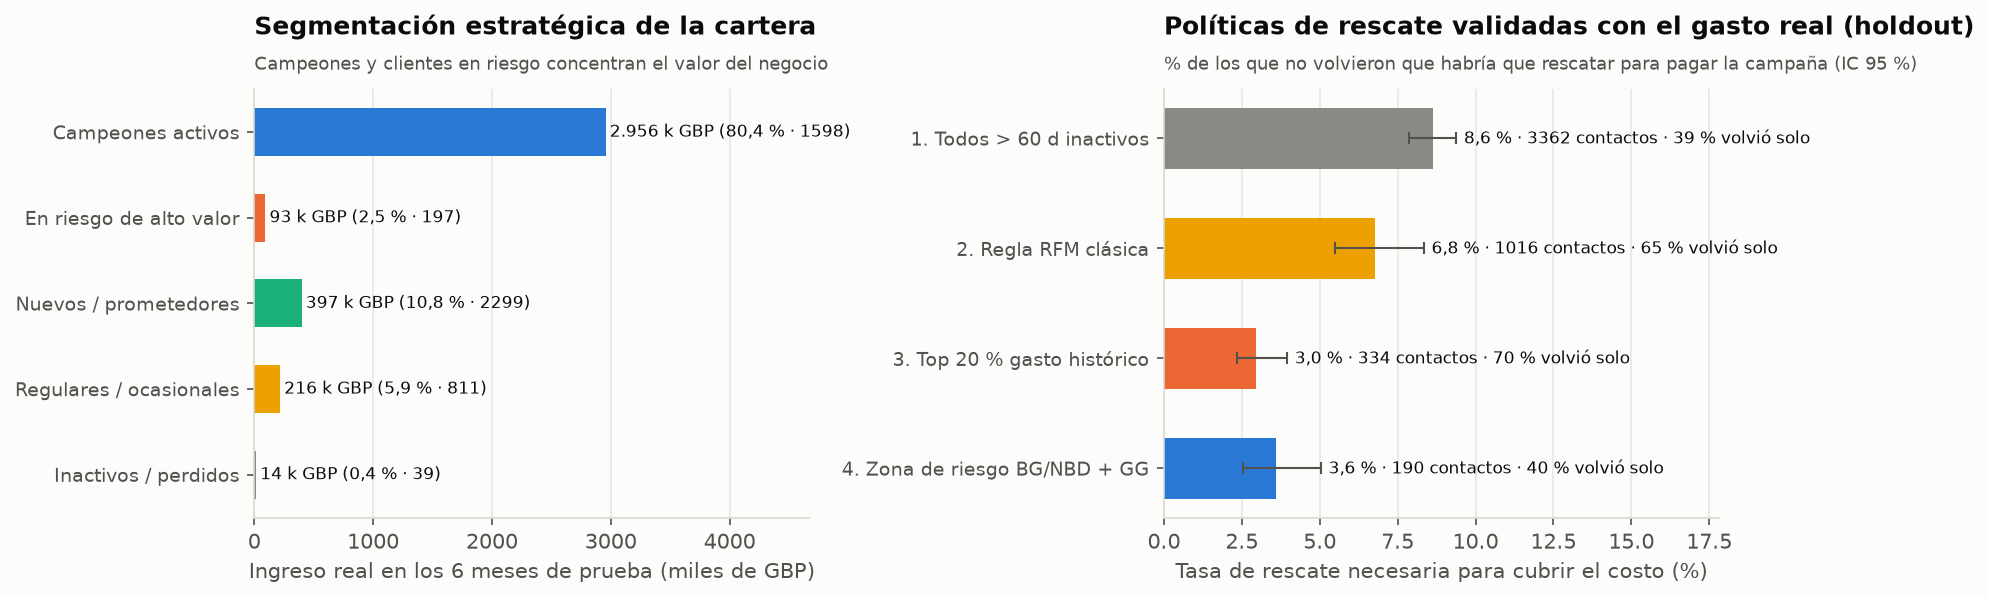

In [5]:
politicas = pd.read_csv(config.REPORTES / "politicas_retencion.csv")
display(politicas.drop(columns=["pct_cartera"]))
display(Image(filename=str(config.FIGURAS / "08_segmentos_y_campana_retencion.png")))

**Resultado:** las políticas 3 (top 20 % de gasto histórico con > 60 días inactivo) y 4 (zona de riesgo de BG/NBD) son las más eficientes, con tasas de rescate de equilibrio de 3,0 % y 3,6 % e **intervalos que se solapan**: con estos datos no se puede decir que una sea mejor que la otra. Se diferencian en a quién eligen: la política 3 contacta a clientes de los que el 70 % volvió solo (riesgo de regalar el incentivo), mientras que la 4 contacta a clientes de los que solo volvió el 40 %, es decir, de verdad en riesgo. Contactar a todos los inactivos (política 1) necesita rescatar más del doble.

## 3.3 · Escenario económico (con supuestos) y su sensibilidad

El escenario calcula el margen recuperado con el propio modelo: $(1 - P(\text{vivo})) \times$ margen esperado si sigue vivo $\times$ efectividad. Supuestos: 25 % de efectividad dentro de $0,20 \le P(\text{vivo}) < 0,70$ y 4 % fuera. Como la política 4 se elige con esa misma fórmula, el escenario la favorece por construcción: **no es una validación**.

,politica,efectividad_rescate,efecto_fuera_zona,clientes_contactados,costo_campana_gbp,margen_recuperado_gbp,ganancia_neta_gbp,roi_pct
0,1. Contactar a todos con > 60 días sin comprar,0.250,0.040,3362,"20,172.000","8,456.756","-11,715.244",-58.077
1,2. Regla RFM (frecuencia >= 2 e inactividad 60...,0.250,0.040,1016,"6,096.000","5,281.301",-814.699,-13.364
2,3. Top 20 % gasto histórico con > 60 d inactiv...,0.250,0.040,334,"2,004.000","4,587.972","2,583.972",128.941
3,4. BG/NBD + Gamma-Gamma (zona de riesgo y bene...,0.250,0.040,190,"1,140.000","6,045.366","4,905.366",430.295


efecto_fuera_zona                                    0.000                           0.040                        
efectividad_rescate                                  0.050   0.100   0.250   0.400   0.050   0.100   0.250   0.400
politica                                                                                                          
1. Contactar a todos con > 60 días sin comprar     -93.000 -86.000 -66.000 -46.000 -85.000 -78.000 -58.000 -38.000
2. Regla RFM (frecuencia >= 2 e inactividad 60–... -86.000 -72.000 -30.000  11.000 -69.000 -55.000 -13.000  28.000
3. Top 20 % gasto histórico con > 60 d inactividad -62.000 -24.000  91.000 205.000 -23.000  15.000 129.000 243.000
4. BG/NBD + Gamma-Gamma (zona de riesgo y benef...   6.000 112.000 430.000 748.000   6.000 112.000 430.000 748.000

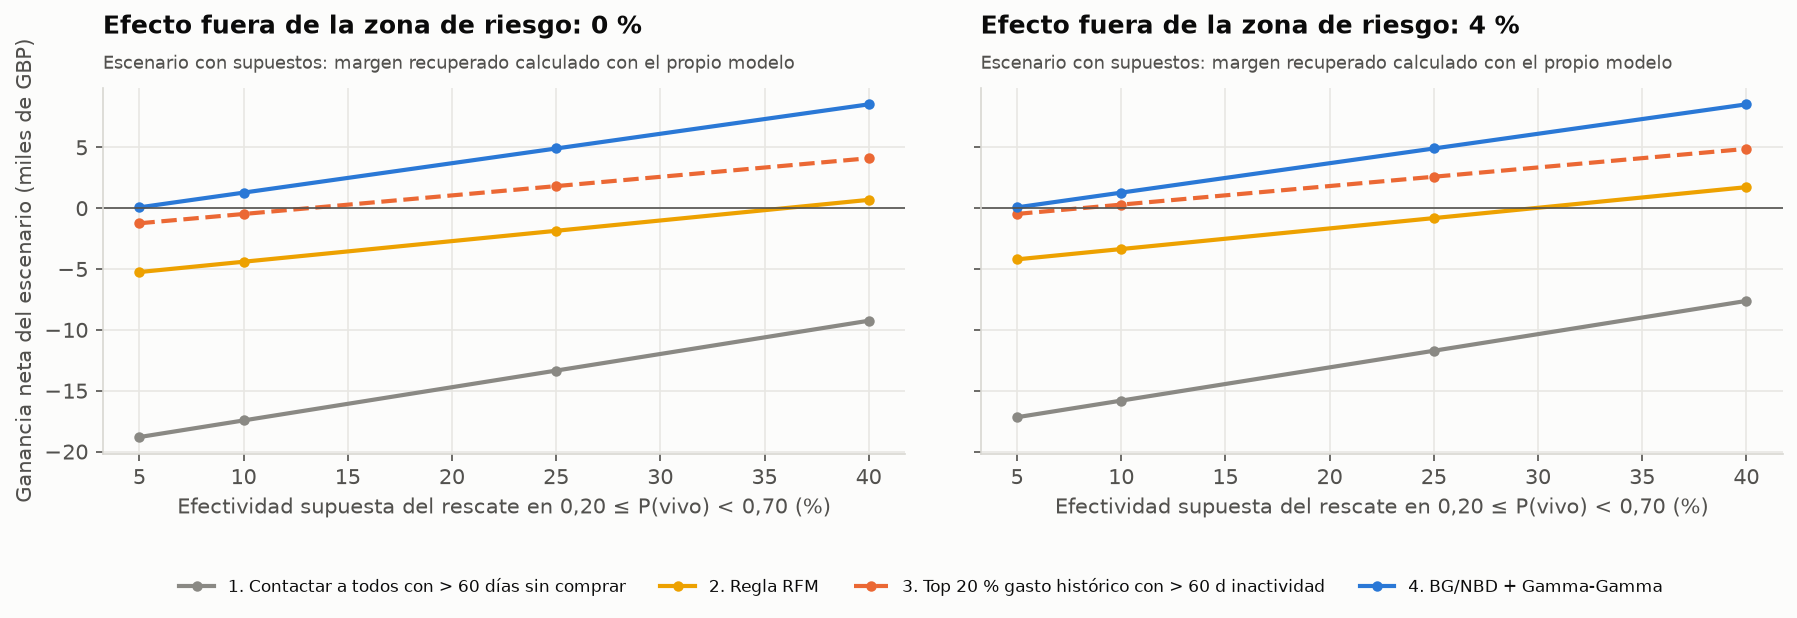

In [6]:
escenario = pd.read_csv(config.REPORTES / "politicas_escenario.csv")
display(escenario)
sens = pd.read_csv(config.REPORTES / "politicas_sensibilidad.csv")
display(sens.pivot_table(index="politica", columns=["efecto_fuera_zona", "efectividad_rescate"], values="roi_pct").round(0))
display(Image(filename=str(config.FIGURAS / "09_sensibilidad_escenario.png")))

El ROI del escenario va de +6 % (efectividad 5 %) a +748 % (efectividad 40 %) para la política 4: la cifra depende casi por completo del supuesto. Lo que sí es robusto es el orden: contactar a todos los inactivos pierde dinero en todos los supuestos probados.

## 3.4 · Lista priorizada de rescate

In [7]:
top_rescate = pd.read_csv(config.REPORTES / "top100_clientes_rescate.csv")
print(f"Clientes seleccionados por la política 4: {int(cartera['conviene_contactar_rescate'].sum())} (todos del segmento «En riesgo de alto valor», que tiene {int((cartera['segmento'] == 'En riesgo de alto valor').sum())})")
print(f"De ellos volvieron solos en la prueba: {cartera.loc[cartera['conviene_contactar_rescate'], 'compras_holdout'].gt(0).mean() * 100:.1f} %")
top_rescate.head(15)

Clientes seleccionados por la política 4: 190 (todos del segmento «En riesgo de alto valor», que tiene 197)
De ellos volvieron solos en la prueba: 40.0 %


,customer_id,frecuencia,recencia_dias,edad_dias,inactividad_dias,ticket_medio_acotado,prob_vivo,prob_recompra,compras_esperadas,ticket_esperado,clv_neto,margen_en_riesgo_gbp,beneficio_neto_rescate_gbp,segmento
0,13093,42,460.000,552.000,92.000,"1,249.171",0.232,0.232,2.869,"1,224.722","1,018.240","3,496.464",868.116,En riesgo de alto valor
1,15523,13,349.000,554.000,205.000,"1,155.766",0.294,0.286,1.166,"1,089.606",368.077,914.398,222.600,En riesgo de alto valor
2,17377,55,482.000,554.000,72.000,256.845,0.282,0.282,4.537,259.830,341.674,901.568,219.392,En riesgo de alto valor
3,15808,20,432.000,555.000,123.000,816.135,0.605,0.602,3.618,791.528,830.012,560.161,134.040,En riesgo de alto valor
4,18251,6,272.000,534.000,262.000,"2,210.775",0.542,0.451,1.086,"1,900.589",598.180,522.349,124.587,En riesgo de alto valor
5,14866,5,78.000,261.000,183.000,792.624,0.315,0.289,0.970,713.465,200.693,452.664,107.166,En riesgo de alto valor
6,12454,2,26.000,238.000,212.000,"3,000.000",0.536,0.385,0.842,"2,005.002",489.452,437.893,103.473,En riesgo de alto valor
7,13206,11,332.000,549.000,217.000,661.829,0.353,0.336,1.204,634.688,221.388,420.440,99.110,En riesgo de alto valor
8,14134,10,347.000,546.000,199.000,"1,046.219",0.549,0.515,1.721,974.428,486.162,413.282,97.321,En riesgo de alto valor
9,12433,4,110.000,293.000,183.000,"1,763.247",0.597,0.510,1.387,"1,440.077",579.071,404.418,95.105,En riesgo de alto valor


## 3.5 · Prueba en vivo de la API FastAPI

In [8]:
cliente_api = TestClient(app)
resp1 = cliente_api.post("/valorar", json={"id_cliente": "13093", "frecuencia": 6, "recencia_dias": 240, "edad_dias": 490, "ticket_medio": 520.0})
print(json.dumps(resp1.json(), indent=2, ensure_ascii=False))
resp2 = cliente_api.post("/priorizar?modo=rescate&capacidad=2", json={"clientes": [
    {"id_cliente": "VIP_ACTIVO", "frecuencia": 12, "recencia_dias": 480, "edad_dias": 500, "ticket_medio": 600.0},
    {"id_cliente": "EN_RIESGO_1", "frecuencia": 6, "recencia_dias": 230, "edad_dias": 500, "ticket_medio": 650.0},
    {"id_cliente": "EN_RIESGO_2", "frecuencia": 4, "recencia_dias": 210, "edad_dias": 460, "ticket_medio": 480.0},
    {"id_cliente": "PERDIDO", "frecuencia": 9, "recencia_dias": 60, "edad_dias": 520, "ticket_medio": 400.0}]})
pd.DataFrame(resp2.json()["clientes"])[["id_cliente", "ranking", "prob_vivo", "segmento", "beneficio_neto_rescate_gbp", "seleccionado"]]

{
  "prob_vivo": 0.5037,
  "prob_recompra": 0.4284,
  "compras_esperadas": 1.087,
  "ticket_esperado_gbp": 498.3,
  "ingreso_esperado_gbp": 541.56,
  "clv_neto_gbp": 156.96,
  "inactividad_dias": 250.0,
  "segmento": "En riesgo de alto valor",
  "accion_recomendada": "Campaña prioritaria de reactivación personalizada (rescate)",
  "conviene_contactar_rescate": true,
  "beneficio_neto_rescate_gbp": 34.02,
  "id_cliente": "13093"
}


,id_cliente,ranking,prob_vivo,segmento,beneficio_neto_rescate_gbp,seleccionado
0,EN_RIESGO_1,1,0.419,En riesgo de alto valor,49.980,True
1,EN_RIESGO_2,2,0.670,En riesgo de alto valor,12.160,True
2,VIP_ACTIVO,3,0.984,Campeones activos,-6.000,False
3,PERDIDO,4,0.000,Inactivos / perdidos,-6.000,False


## 3.6 · App Streamlit

`streamlit run app/app.py --server.port 8615` abre una ficha por cliente (CLV, $P(\text{vivo})$, segmento, acción recomendada y lo que pasó realmente en la prueba), un simulador y las tablas de la cartera. Usa el mismo motor que la API, así que sus cifras coinciden con `reports/cartera_clientes.csv`:

{'clv_neto_gbp': 1018.24, 'prob_vivo': 0.2316, 'segmento': 'En riesgo de alto valor', 'accion_recomendada': 'Campaña prioritaria de reactivación personalizada (rescate)'}


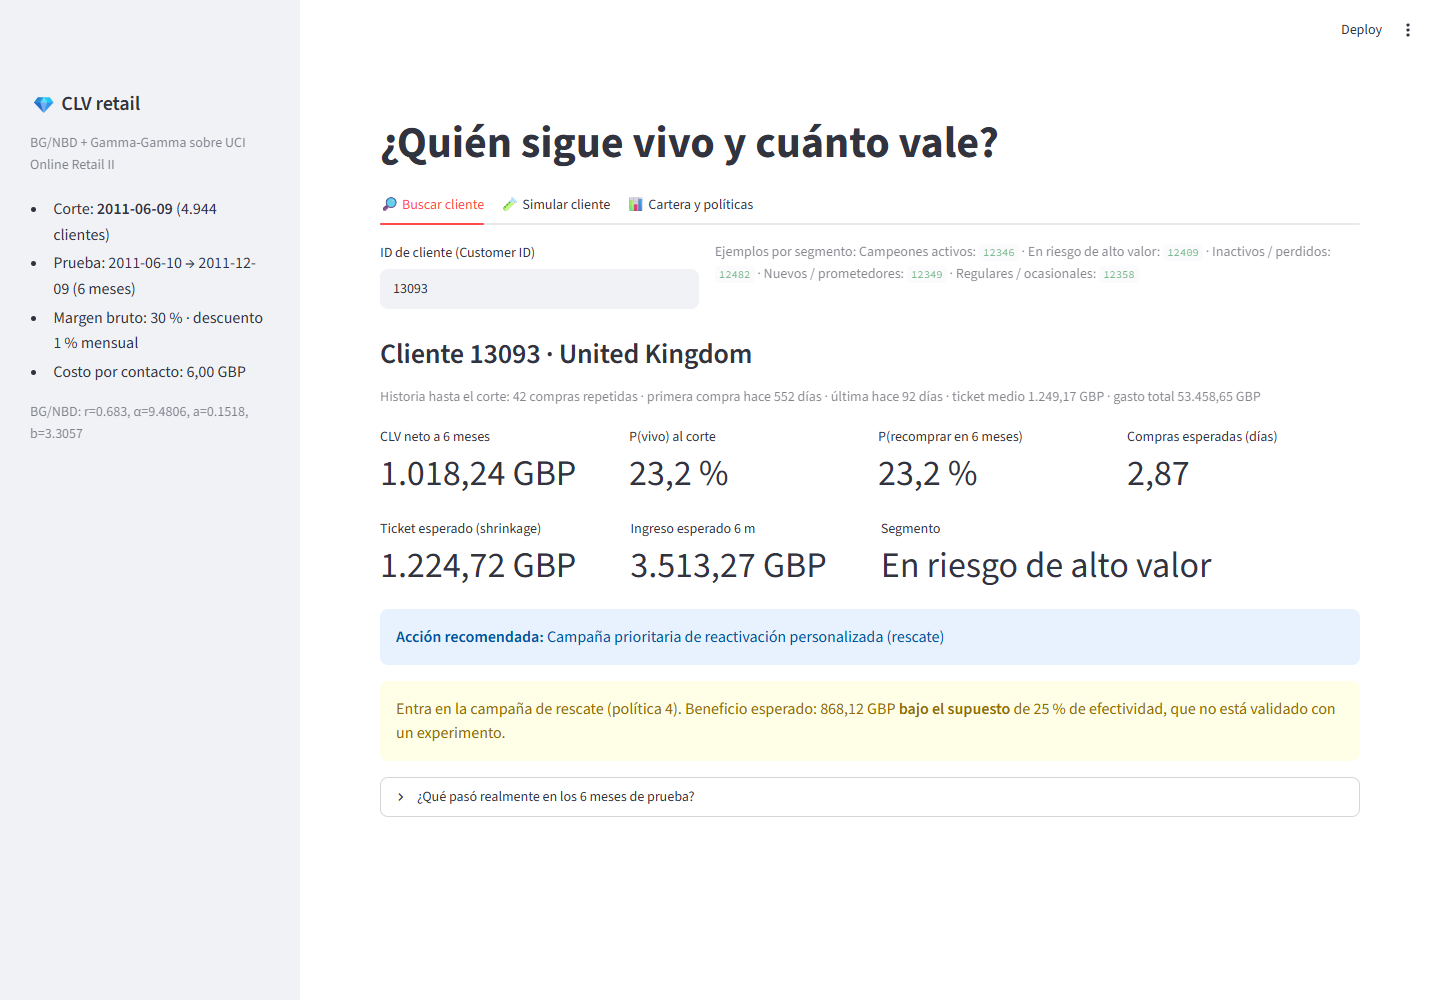

In [9]:
import importlib.util, logging
import streamlit  # noqa: F401  (silencia el aviso «No runtime found» fuera de `streamlit run`)
logging.getLogger("streamlit.runtime.caching.cache_data_api").setLevel(logging.ERROR)
spec = importlib.util.spec_from_file_location("app_clv", RAIZ / "app" / "app.py")
app_mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(app_mod)
fila = app_mod.buscar_cliente(cartera, "13093")
ficha = app_mod.ficha_cliente(fila)
print({k: ficha[k] for k in ["clv_neto_gbp", "prob_vivo", "segmento", "accion_recomendada"]})
display(Image(filename=str(config.FIGURAS / "10_app_streamlit.png"), width=900))